# Census comparison areas, 2010–2022

This notebook follows tract polygons and census counts into `census_comparison_areas_2010_2022.gpkg`. A real split group is carried through matching, grouping, merging, and indicator calculation below. Running all cells builds the national file; the same cells run through `datasets/run.py census`.

**Source:** IBGE polygons and censobr v0.5.0 tables preserved in the original project. [Project settings](../project.toml) locate the inputs; the [archived acquisition script](https://github.com/fab1s/brazil-project/blob/archive/full-project-2026-10-27/code/scripts/r/acquire_census.R) records retrieval. Exact historical downloads are unavailable. [Column definitions](CODEBOOK.md).

In [1]:
%run ../_shared.py
ctx = notebook_context("census")
import pandas as pd
import geopandas as gpd
import numpy as np
import shapely
from IPython.display import display

## 1. Input geography

The two years have different tract boundaries and counts. A tract code therefore cannot provide a direct comparison across years. The saved crosswalk records the original links; the prepared 2022 geometry also retains separate pieces of some tracts. The final analysis needs one complete feature per comparison group.

<details><summary>Geometry preparation</summary>

Overlap calculations use EPSG:5880. The 2010 input is transformed to that CRS, uses the configured precision grid, and has invalid geometry repaired in a derived copy. The usual run retains the original prepared 2022 pieces. Only derived group geometry is dissolved; the source files remain intact.

</details>

In [2]:
display(geopackage_inventory(ctx.path("census", "tracts")))
display(geopackage_inventory(ctx.path("census", "baseline_lookup")))

,Layer,Rows,Geometry,CRS
0,2000_urban,128012,Unknown,EPSG:4674
1,2000_rural,68406,Polygon,EPSG:4674
2,2010,316574,Unknown,EPSG:4674
3,2022,472778,Polygon,EPSG:4674


,Layer,Rows,Geometry,CRS
0,2010,497490,None,None
1,2022,468073,None,None


## 2. Tract matching and comparison groups

The original method chooses each tract's largest polygon overlap in the other year, in **both directions**, then combines the links. A chain of connected links becomes one `common_id`. One tract in each year is one-to-one; one 2010 tract linked to several 2022 tracts is a split; a merge is the reverse. Several on both sides form a complex group.

The configured national run **checks the preserved links for positive area and rebuilds their connected groups**. It does not freshly rank every national overlap. Optional `recompute_harmonisation = true` recalculates largest overlaps nationally; equal areas follow target row order. Edge-only and point-only contacts are rejected in either mode. Unchanged memberships retain their IDs; changed groups get stable IDs derived from their members. [Implementation: source_correspondence(), largest_overlap(), grouped_crosswalk()](../shared/brazil_project/harmonisation/census.py).

Unmatched tracts remain in a separate inventory. The coverage table reports their known population and the number lacking population values; those known totals exclude the unknown values.

Using saved harmonisation outputs


,Run mode,Comparison groups,Rejected saved links
0,validated_original_correspondence,287178,0


,Year,Matched tract IDs,Unmatched tract IDs,Known residents in unmatched tracts,Unmatched tracts with unknown population
0,2010,316558,16,87.0,12
1,2022,468073,24,281.0,0


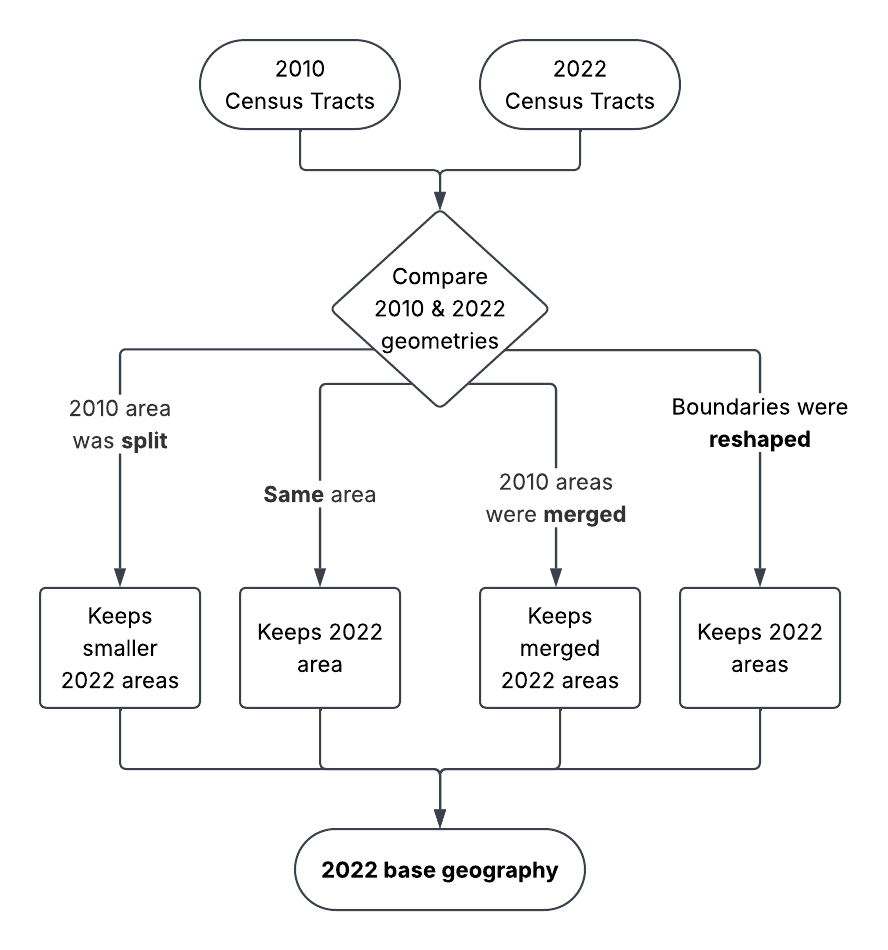

In [3]:
process_stage(ctx, "harmonisation")
from brazil_project.harmonisation.census import load_bundle
from processing import example_tracts
bundle, manifest = load_bundle(ctx, names=["crosswalk"])
common_id, old, new = example_tracts(ctx, bundle)
example_lookups = {year: bundle[f"lookup_{year}"].query("common_id == @common_id")
                   for year in (2010, 2022)}
saved_links = bundle["crosswalk"].query("common_id == @common_id").copy()
saved_shape = bundle["common_geometry_2022"].query("common_id == @common_id").copy()
stage_report = json.loads(ctx.require(ctx.artifact("harmonisation", "report.json")).read_text())
assert stage_report["version"] == manifest["version"]
display(pd.DataFrame([{"Run mode": manifest["mode"], "Comparison groups": len(bundle["group_sizes"]),
                       "Rejected saved links": stage_report["rejected_edges"]}]))
coverage = []
for year, values in manifest["population_coverage"].items():
    population = values["measures"]["population"]
    coverage.append({"Year": year, "Matched tract IDs": values["matched_tract_ids"],
        "Unmatched tract IDs": values["unmatched_tract_ids"],
        "Known residents in unmatched tracts": population["unmatched_known_total"],
        "Unmatched tracts with unknown population": population["unmatched_missing_values"]})
display(pd.DataFrame(coverage))
del bundle
show_image(ctx, "datasets/census/harmonisation.png", width=600)

**Diagram:** the original project graphic shows the choice of 2022 base geography. The final research file merges every complete `common_id` group, including split groups; individual 2022 pieces remain in the reference outputs.

## 3. Real split: overlap links

For readability, the example selects a one-to-two split touching Belo Horizonte when available. The table shows overlap areas **between this group's members** and marks the links in the saved crosswalk. Surrounding candidates are omitted, so this is an illustration rather than a new national matching test.

In this split, the 2010 tract chooses its larger 2022 overlap; both 2022 tracts choose the 2010 tract. Combining the two directions keeps both links. The example recomputation below is limited to these members and is compared with the saved link set.

In [4]:
pairs = old.rename_geometry("geometry_2010").merge(
    new.rename_geometry("geometry_2022"), how="cross")
pairs["overlap_m2"] = shapely.area(shapely.intersection(
    pairs.geometry_2010.to_numpy(), pairs.geometry_2022.to_numpy()))
pairs = pairs.merge(saved_links[["id_2010", "id_2022"]].assign(saved_link=True),
                    on=["id_2010", "id_2022"], how="left", validate="many_to_one")
display(pairs[["id_2010", "id_2022", "overlap_m2", "saved_link"]])

from brazil_project.harmonisation.census import largest_overlap, grouped_crosswalk
choices_2010 = largest_overlap(old, new, "id_2010", "id_2022").assign(direction="2010 → 2022")
choices_2022 = largest_overlap(new, old, "id_2022", "id_2010").assign(direction="2022 → 2010")
display(pd.concat([choices_2010, choices_2022], ignore_index=True))
example_links = pd.concat([choices_2010, choices_2022])[["id_2010", "id_2022"]].drop_duplicates()
assert set(map(tuple, example_links.to_numpy())) == set(map(tuple, saved_links[["id_2010", "id_2022"]].to_numpy()))
crosswalk, lookup_2010, lookup_2022, group_sizes = grouped_crosswalk(example_links, original=saved_links)
display(crosswalk.reset_index(drop=True))
display(group_sizes)

,id_2010,id_2022,overlap_m2,saved_link
0,310620005620002,310620005620002,8827.485875,True
1,310620005620002,310620005620538,11177.737168,True


,id_2010,id_2022,direction
0,310620005620002,310620005620538,2010 → 2022
1,310620005620002,310620005620002,2022 → 2010
2,310620005620002,310620005620538,2022 → 2010


,id_2010,id_2022,common_id
0,310620005620002,310620005620538,95335
1,310620005620002,310620005620002,95335


,common_id,n_2010,n_2022,relationship
0,95335,1,2,2010_to_2022_split


## 4. Merged 2022 group geometry

Every 2022 piece carrying this `common_id` is merged. A split therefore produces **one final group feature**, rather than repeating group totals on its smaller tract pieces. Original pieces remain in the intermediate bundle. Municipality selection retains entire connected groups, including pieces beyond the selected boundary.

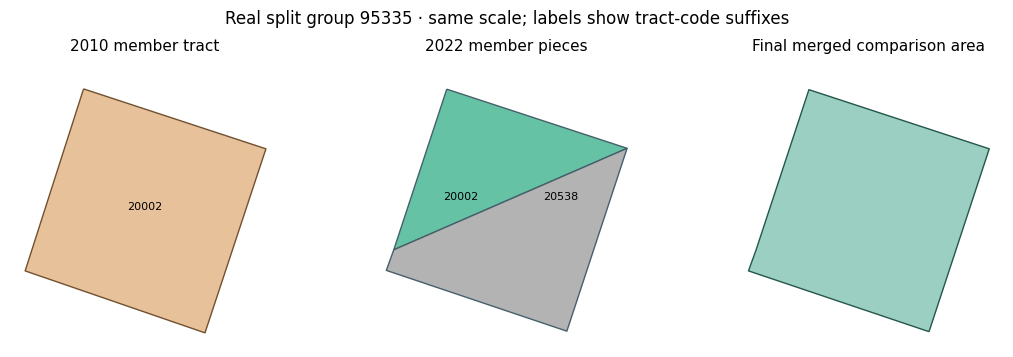

,2022 pieces,Final features,Equal-area denominator (km²)
0,2,1,0.01975


In [5]:
new_group = new.merge(lookup_2022[["id_2022", "common_id"]], on="id_2022", validate="many_to_one")
new_group.geometry = shapely.make_valid(new_group.geometry.array)
merged = new_group[["common_id", "geometry"]].dissolve(by="common_id", as_index=False)
assert shapely.equals(merged.geometry.iloc[0], saved_shape.geometry.iloc[0])

# Density's area denominator transforms the pieces before merging.
area_km2 = new_group.to_crs(6933).dissolve(by="common_id").area.iloc[0] / 1e6
np.testing.assert_allclose(area_km2, saved_shape.area_km2.iloc[0], rtol=0, atol=1e-9)
from processing import plot_group
show_figure(plot_group(old, new, merged, common_id))
display(pd.DataFrame([{"2022 pieces": len(new_group), "Final features": len(merged),
                       "Equal-area denominator (km²)": area_km2}]))

## 5. Population indicator calculation

Annual tract values are joined through each year's lookup, once per tract ID, so repeated geometry pieces do not multiply residents. Numerators and denominators are summed **before division**; averaging tract percentages would give a different result. Here the Black-or-Brown numerator uses `pessoa03_V003 + pessoa03_V005` in 2010 and `raca_V01318 + raca_V01320` in 2022. Their denominators are `pessoa03_V001` and `V0001`.

This combined indicator follows the original rule: missing component counts become zero and group sums use available denominator values; a zero denominator produces no ratio. Other indicators retain their own missingness rules. [Production calculations: temporal.py](../shared/brazil_project/indicators/temporal.py).

In [6]:
process_stage(ctx, "indicators")
example_totals = []
for year, table_name, numerator_columns, denominator in [
    (2010, "2010_pessoa", ["pessoa03_V003", "pessoa03_V005"], "pessoa03_V001"),
    (2022, "2022_pessoas", ["raca_V01318", "raca_V01320"], "V0001")]:
    ids = example_lookups[year][f"id_{year}"].tolist()
    columns = ["code_tract", *numerator_columns] + ([denominator] if year == 2010 else [])
    raw = pd.read_parquet(ctx.artifact("census", table_name + ".parquet"), columns=columns,
                          filters=[("code_tract", "in", ids)])
    if year == 2022:
        basic = pd.read_parquet(ctx.artifact("census", "2022_basico.parquet"),
            columns=["code_tract", denominator], filters=[("code_tract", "in", ids)])
        raw = basic.merge(raw, on="code_tract", how="left", validate="one_to_one")
    display(raw)
    counts = raw.rename(columns={"code_tract": f"id_{year}", denominator: "population"})
    counts["black_brown_population"] = counts[numerator_columns].fillna(0).sum(axis=1)
    counts = counts.merge(example_lookups[year][[f"id_{year}", "common_id"]],
                          on=f"id_{year}", validate="one_to_one")
    totals = counts.groupby("common_id")[["black_brown_population", "population"]].sum(min_count=0)
    totals["share"] = totals.black_brown_population / totals.population.where(totals.population > 0)
    totals["year"] = year
    example_totals.append(totals.reset_index())
example_totals = pd.concat(example_totals, ignore_index=True)
display(example_totals)

saved_indicator = ctx.table("indicators", "black_brown").query("common_id == @common_id").iloc[0]
for row in example_totals.itertuples():
    assert row.black_brown_population == saved_indicator[f"black_brown_pop_{row.year}"]
    assert row.population == saved_indicator[f"pop_{row.year}"]
    np.testing.assert_allclose(row.share, saved_indicator[f"black_brown_ratio_{row.year}"], rtol=0, atol=1e-12)
print("Change (percentage points):", 100 * (example_totals.share.iloc[1] - example_totals.share.iloc[0]))

Using saved indicators outputs


,code_tract,pessoa03_V003,pessoa03_V005,pessoa03_V001
0,310620005620002,9.0,52.0,587.0


,code_tract,V0001,raca_V01318,raca_V01320
0,310620005620002,448.0,7.0,55.0
1,310620005620538,404.0,6.0,45.0


,common_id,black_brown_population,population,share,year
0,95335,61.0,587.0,0.103918,2010
1,95335,113.0,852.0,0.132629,2022


Change (percentage points): 2.8710879701833947


## 6. Remaining indicator calculations

All 13 indicators are covered below. The stage calculates each measure from its year-specific source columns. [Production definitions](../shared/brazil_project/indicators/temporal.py) and the [codebook](CODEBOOK.md) provide the exact source fields and export names.

| Measure | Numerator or calculation | Denominator |
| --- | --- | --- |
| Black, Brown, Black-or-Brown population | Residents in the relevant race categories | Population available for that race calculation |
| Literacy | Literate residents aged 15+ | Residents aged 15+ |
| Rudimentary sanitation | Households in the specified rudimentary sanitation categories | Applicable households |
| Water network | Households supplied through the network | Applicable households |
| Waste collection | Households using the included collection methods | Applicable households |
| Sewer/septic | Households using the included sewer or septic systems | Applicable households |
| Houses, village/condominium houses, apartments | Households in each housing type, calculated separately | Applicable households |
| Income | Sum of tract mean income × usable household-head weight | Sum of those usable weights |
| Population density | Population | Group area in km² |

Missingness follows the original definitions. Multi-component counts can treat missing parts as zero; housing and density retain unavailable all-missing denominators; income uses only valid means with positive weights. An available estimate can therefore have partial input coverage.

**Income:** the 2010 tract mean is `V022 / V021`, weighted by `V020`; the 2022 mean is `V06004`, weighted by `V06001`. The 2010 group mean is multiplied by the configured `6645.74 / 3200.06` inflation ratio to express July 2022 prices. These differing census definitions remain a qualification.

**Density and change:** density uses the equal-area denominator demonstrated above. Share changes are percentage points; density and income changes are relative percentages and require positive baseline values. Missing years remain unavailable.

In [7]:
income = ctx.table("indicators", "income").query("common_id == @common_id")
display(income[["common_id", "income_2010", "income_2022", "heads_used_2010", "heads_used_2022",
                "complete_2010", "complete_2022", "income_change_pct"]])

,common_id,income_2010,income_2022,heads_used_2010,heads_used_2022,complete_2010,complete_2022,income_change_pct
281997,95335,27584.567613,20668.245477,189.0,325.0,True,True,-25.073158


## 7. Final research file

The exporter joins all saved indicators to the merged 2022 geometry. It follows the map-field validity rules: out-of-range shares and negative/nonfinite density values, with their associated counts, remain unavailable. It writes English columns and retains their source mappings in `field_dictionary`. Fields are shared only when their units, values, and missingness are exactly equal. `overview` provides simplified municipality display summaries; complete groups can cross municipal borders, so these summaries must not be summed as independent national areas. [Export code](../shared/scripts/export_census_gpkg.py).

In [8]:
from processing import export_geopackage, inspect_final
result = inspect_final(ctx.root, preview=True) if ctx.notebook_from_saved else export_geopackage(ctx.root)
show_final(ctx, result)
display(sql_table(result["file"], "SELECT original_column, english_column, unit FROM field_dictionary WHERE layer='comparison_areas' LIMIT 12"))

,File,Layer,Features,CRS
0,datasets/census/census_comparison_areas_2010_2...,comparison_areas,287178,EPSG:5880


SHA-256: d773ae277380596624415ec33ecbfbc8d8c46b2d3fee498fb2ff57f2d01b3427


,original_column,english_column,unit
0,common_id,common_id,identifier
1,relationship,tract_relationship,category
2,n_2010,tracts_2010,tracts
3,population_density_2010,population_density_2010,people/km2
4,population_density_n2010,total_population_2010,people
5,population_density_d2010,area_km2_2010,km2
6,black_2010,black_share_2010,fraction
7,black_n2010,black_population_2010,people
8,black_d2010,total_population_2010,people
9,brown_2010,brown_share_2010,fraction


## 8. Export verification

This checks that the explained counts and proportions reached the final output. The pipeline also verifies national IDs, memberships, input versions, missingness, CRS, and source-to-export geometry. The example is a trace through one group; it does not establish national scientific validity.

**Research assumption:** the years' group footprints can differ. The study assumes those differences do not materially change the inhabited population; that remains unverified for individual groups. Unmatched tracts and footprint diagnostics are preserved separately.

In [9]:
exported = sql_table(result["file"], "SELECT common_id, black_brown_population_2010, black_brown_population_2022, black_brown_share_2010, black_brown_share_2022 FROM comparison_areas WHERE common_id=?", (common_id,))
display(exported)
for row in example_totals.itertuples():
    assert exported[f"black_brown_population_{row.year}"].iloc[0] == row.black_brown_population
    np.testing.assert_allclose(exported[f"black_brown_share_{row.year}"].iloc[0], row.share, rtol=0, atol=1e-12)
print("Example source counts, group calculation, merged geometry, and exported values agree.")

,common_id,black_brown_population_2010,black_brown_population_2022,black_brown_share_2010,black_brown_share_2022
0,95335,61.0,113.0,0.103918,0.132629


Example source counts, group calculation, merged geometry, and exported values agree.


<details><summary>Execution verification</summary>

The full national notebook command completed on 2026-10-27. All 287,178 comparison-area records and 5,570 overview records matched the preceding reviewed export in attributes and geometry blobs. The worked example also matched its saved indicator and final values.

</details>